In [1]:
from dotenv import load_dotenv
load_dotenv()

True

In [5]:
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import OpenAIEmbeddings
from langchain_community.vectorstores import InMemoryVectorStore

from langchain_groq import ChatGroq
from langgraph.graph import StateGraph, START, END
from pydantic import BaseModel, Field
from langchain_community.tools import Tool

In [4]:
##load document
loader=PyPDFLoader("../data/medical_report.pdf")
docs=loader.load()

##split document
splitter=RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
docs=splitter.split_documents(docs)

##create vector embeddings
embed=OpenAIEmbeddings(model="text-embedding-3-large")
vector_store=InMemoryVectorStore.from_documents(
    embedding=embed,
    documents=docs
)

In [10]:
llm=ChatGroq(model="openai/gpt-oss-20b")

In [7]:
class RagState(BaseModel):
    question:str=Field(description="user question")
    documents:list=[]
    context:str=Field(description="data context", default="")
    answer:str=Field(description="Final answer", default="")

In [11]:
def retrieve_node(state:RagState)->RagState:
    docs=vector_store.similarity_search(query=state.question)
    state.documents=docs
    return state

def context_node(state:RagState)->RagState:
    context=""
    for doc in state.documents:
        context+= doc.page_content + "\n\n"
    state.context=context
    return state

def generate_code(state:RagState)->RagState:
    prompt = f"""
        You are a assistant and provide the answer for user question based on the provided context.
        If you don't find the relevant answer, then just say 'I dont know.'.
        Context is: {state.context},
        Questions is: {state.question}
    """
    res=llm.invoke(prompt)
    state.answer=res.content
    return state


In [16]:
graph=StateGraph(RagState)

graph.add_node("retrieve_node", retrieve_node)
graph.add_node("context_node", context_node)
graph.add_node("generate_code", generate_code)

graph.add_edge(START, "retrieve_node")
graph.add_edge("retrieve_node", "context_node")
graph.add_edge("context_node", "generate_code")
graph.add_edge("generate_code", END)

graph=graph.compile()


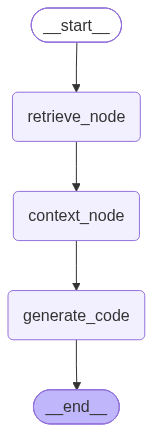

In [17]:
from IPython.display import Image
Image(graph.get_graph().draw_mermaid_png())

In [18]:
res=graph.invoke({"question": "what is the name of patient"})

In [26]:
print(res["answer"])

The patient’s name is **Ms. Nikita Chudhary**.
